# **Importações**

In [308]:
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import joblib
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# **Carregando** **Dataset**

In [309]:
!pip install -q kagglehub

# Baixar dataset
path = kagglehub.dataset_download("imtkaggleteam/diabetes")

# Mostrar arquivo disponível
print("Arquivo encontrado:")
print(os.listdir(path))

Using Colab cache for faster access to the 'diabetes' dataset.
Arquivo encontrado:
['diabetes.csv']


# **Exploratory** **Data** **Analysis** (**EDA**)

### Verificando dataset

In [310]:
df = pd.read_csv(os.path.join(path, "diabetes.csv"))

df.head()

,id,chol,stab.glu,hdl,ratio,glyhb,location,age,gender,height,weight,frame,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn
0,1000,203.0,82,56.0,3.6,4.31,Buckingham,46,female,62.0,121.0,medium,118.0,59.0,NaN,NaN,29.0,38.0,720.0
1,1001,165.0,97,24.0,6.9,4.44,Buckingham,29,female,64.0,218.0,large,112.0,68.0,NaN,NaN,46.0,48.0,360.0
2,1002,228.0,92,37.0,6.2,4.64,Buckingham,58,female,61.0,256.0,large,190.0,92.0,185.0,92.0,49.0,57.0,180.0
3,1003,78.0,93,12.0,6.5,4.63,Buckingham,67,male,67.0,119.0,large,110.0,50.0,NaN,NaN,33.0,38.0,480.0
4,1005,249.0,90,28.0,8.9,7.72,Buckingham,64,male,68.0,183.0,medium,138.0,80.0,NaN,NaN,44.0,41.0,300.0


In [311]:
print("Dimensões do dataset:", df.shape)

print("\nColunas:")
print(df.columns.tolist())

print("\nInformações:")
df.info()

#Verificar dados faltantes
print("\nQuantidade de dados faltantes:")
print(df.isnull().sum())

#Verificar duplicatas
print("\nQuantidade de duplicatas:", df.duplicated().sum())

Dimensões do dataset: (403, 19)

Colunas:
['id', 'chol', 'stab.glu', 'hdl', 'ratio', 'glyhb', 'location', 'age', 'gender', 'height', 'weight', 'frame', 'bp.1s', 'bp.1d', 'bp.2s', 'bp.2d', 'waist', 'hip', 'time.ppn']

Informações:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403 entries, 0 to 402
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        403 non-null    int64  
 1   chol      402 non-null    float64
 2   stab.glu  403 non-null    int64  
 3   hdl       402 non-null    float64
 4   ratio     402 non-null    float64
 5   glyhb     390 non-null    float64
 6   location  403 non-null    object 
 7   age       403 non-null    int64  
 8   gender    403 non-null    object 
 9   height    398 non-null    float64
 10  weight    402 non-null    float64
 11  frame     391 non-null    object 
 12  bp.1s     398 non-null    float64
 13  bp.1d     398 non-null    float64
 14  bp.2s     141 non-null    float64
 1

A variável alvo foi criada com base na hemoglobina glicada (glyhb), considerando valores iguais ou superiores a 6,5 como 1 (diabético) e valores abaixo disso como 0 (não diabético). Essa classificação permite treinar os modelos para identificar os dois grupos.

In [312]:
# Criar a variável alvo
df['Classe'] = df['glyhb'].apply(lambda x: 1 if x >= 6.5 else 0 if pd.notna(x) else None)

# Remover os casos sem diagnóstico
df = df.dropna(subset=['Classe']).copy()
df['Classe'] = df['Classe'].astype(int)

# Definir diagnósticos
nomes_classes = {
    0: 'Não diabético',
    1: 'Diabético'
}

df['Diagnóstico'] = df['Classe'].map(nomes_classes)

# Removendo as variáveis categóricas
df = df.drop(columns=['location', 'gender', 'frame'], errors='ignore')

# Preencher valores vazios
df.fillna(df.mean(numeric_only = True), inplace = True)

df.head()

,id,chol,stab.glu,hdl,ratio,glyhb,age,height,weight,bp.1s,bp.1d,bp.2s,bp.2d,waist,hip,time.ppn,Classe,Diagnóstico
0,1000,203.0,82,56.0,3.6,4.31,46,62.0,121.0,118.0,59.0,152.84058,92.731884,29.0,38.0,720.0,0,Não diabético
1,1001,165.0,97,24.0,6.9,4.44,29,64.0,218.0,112.0,68.0,152.84058,92.731884,46.0,48.0,360.0,0,Não diabético
2,1002,228.0,92,37.0,6.2,4.64,58,61.0,256.0,190.0,92.0,185.00000,92.000000,49.0,57.0,180.0,0,Não diabético
3,1003,78.0,93,12.0,6.5,4.63,67,67.0,119.0,110.0,50.0,152.84058,92.731884,33.0,38.0,480.0,0,Não diabético
4,1005,249.0,90,28.0,8.9,7.72,64,68.0,183.0,138.0,80.0,152.84058,92.731884,44.0,41.0,300.0,1,Diabético


In [313]:
# Verificar se as classes estão balanceadas de acordo com a frequência de cada diagnóstico
df['Diagnóstico'].value_counts()


,count
Diagnóstico,
Não diabético,325
Diabético,65


## Estatística descritiva e visualização de dados

### Variáveis numéricas

In [314]:
cols = ['chol','stab.glu','hdl','ratio','age','height','weight','bp.1s','bp.1d','bp.2s','bp.2d','waist','hip','time.ppn']

df[cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
chol,390.0,207.28,44.66,78.0,179.00,203.50,229.00,443.0
stab.glu,390.0,107.34,53.80,48.0,81.00,90.00,107.75,385.0
hdl,390.0,50.27,17.28,12.0,38.00,46.00,59.00,120.0
ratio,390.0,4.53,1.74,1.5,3.20,4.20,5.40,19.3
age,390.0,46.77,16.44,19.0,34.00,44.50,60.00,92.0
height,390.0,65.98,3.90,52.0,63.00,66.00,69.00,76.0
weight,390.0,177.35,40.39,99.0,150.25,173.00,199.75,325.0
bp.1s,390.0,137.15,22.85,90.0,122.00,136.00,148.00,250.0
bp.1d,390.0,83.29,13.49,48.0,75.00,82.00,90.00,124.0
bp.2s,390.0,152.84,12.88,110.0,152.84,152.84,152.84,238.0


In [315]:
df.groupby('Diagnóstico')[cols].agg(['mean','std']).round(1)

chol       stab.glu         hdl       ratio        age        \
                mean   std     mean   std  mean   std  mean  std  mean   std   
Diagnóstico                                                                    
Diabético      228.8  56.6    189.6  78.9  45.5  18.3   5.6  2.6  58.4  12.8   
Não diabético  203.0  40.6     90.9  24.8  51.2  16.9   4.3  1.4  44.4  16.1   

               ...  bp.2s       bp.2d      waist        hip      time.ppn  \
               ...   mean   std  mean  std  mean  std  mean  std     mean   
Diagnóstico    ...                                                          
Diabético      ...  154.1  10.7  91.4  7.3  40.8  5.6  44.8  5.3    362.3   
Não diabético  ...  152.6  13.3  93.0  6.8  37.3  5.6  42.7  5.6    330.9   

                      
                 std  
Diagnóstico           
Diabético      335.5  
Não diabético  302.1  

[2 rows x 28 columns]

### Correlação

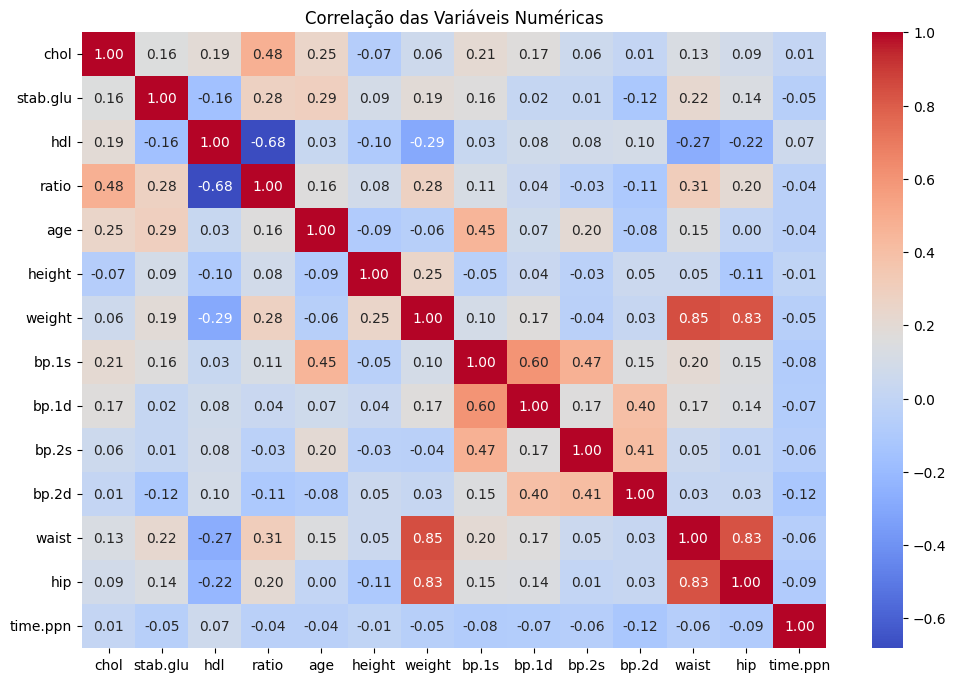

In [316]:
# Correlação variáveis numéricas
correlacao = df[cols].corr()

plt.figure(figsize = (12, 8))

sns.heatmap(correlacao, annot = True, fmt = '.2f',cmap = 'coolwarm')

plt.title('Correlação das Variáveis Numéricas')
plt.show()

**Existe uma relação entre os níveis de colesterol e de glicose dos indivíduos? Como a razão colesterol/HDL varia conforme os níveis de HDL?**

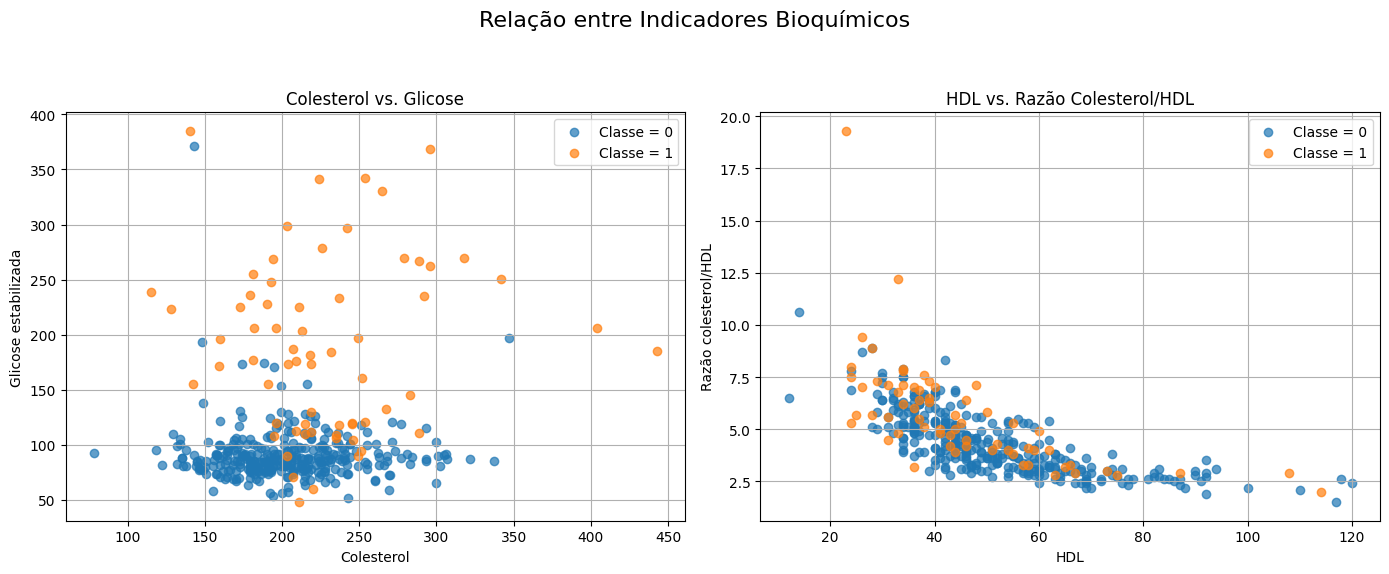

In [319]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Colesterol vs. Glicose
for c in sorted(df['Classe'].dropna().unique()):
    grupo = df[df['Classe'] == c]

    axes[0].scatter(grupo['chol'], grupo['stab.glu'], label=f'Classe = {int(c)}', alpha=0.7)

axes[0].set_xlabel('Colesterol')
axes[0].set_ylabel('Glicose estabilizada')
axes[0].set_title('Colesterol vs. Glicose')
axes[0].legend()
axes[0].grid(True)

# Gráfico 2: HDL vs. Razão colesterol/HDL
for c in sorted(df['Classe'].dropna().unique()):
    grupo = df[df['Classe'] == c]

    axes[1].scatter(grupo['hdl'], grupo['ratio'], label=f'Classe = {int(c)}', alpha=0.7)

axes[1].set_xlabel('HDL')
axes[1].set_ylabel('Razão colesterol/HDL')
axes[1].set_title('HDL vs. Razão Colesterol/HDL')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Relação entre Indicadores Bioquímicos', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()

O gráfico não mostra uma relação forte e clara entre colesterol e glicose. Entretanto, os indivíduos classificados com diabetes apresentam, em geral, valores de glicose mais elevados. Já a razão colesterol/HDL apresenta uma tendência decrescente conforme o HDL aumenta.

**A distribuição do peso em relação à altura apresenta diferenças entre os grupos com e sem diabetes? Os grupos com e sem diabetes apresentam distribuições diferentes circunferência da cintura e do quadril?**

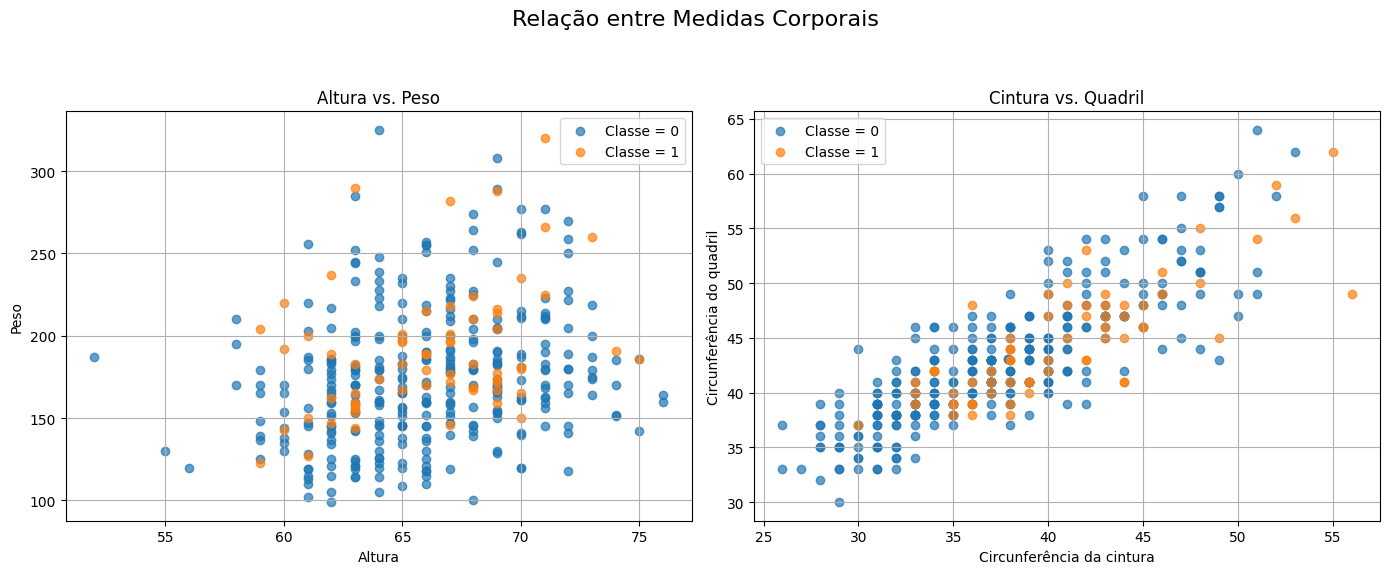

In [320]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Peso vs. Altura
for c in sorted(df['Classe'].dropna().unique()):
    grupo = df[df['Classe'] == c]

    axes[0].scatter(grupo['height'], grupo['weight'], label=f'Classe = {int(c)}', alpha=0.7)

axes[0].set_xlabel('Altura')
axes[0].set_ylabel('Peso')
axes[0].set_title('Altura vs. Peso')
axes[0].legend()
axes[0].grid(True)

# Gráfico 2: Cintura vs. Quadril
for c in sorted(df['Classe'].dropna().unique()):
    grupo = df[df['Classe'] == c]

    axes[1].scatter(grupo['waist'], grupo['hip'], label=f'Classe = {int(c)}', alpha=0.7)

axes[1].set_xlabel('Circunferência da cintura')
axes[1].set_ylabel('Circunferência do quadril')
axes[1].set_title('Cintura vs. Quadril')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Relação entre Medidas Corporais', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()

No gráfico de altura e peso, os grupos apresentam bastante sobreposição, sem diferenças visuais muito claras. Já cintura e quadril apresentam uma relação positiva: quanto maior a circunferência da cintura, maior tende a ser a do quadril. Os dois grupos também apresentam sobreposição nessas medidas.

**Há diferenças na distribuição da pressão arterial entre os grupos com e sem diabetes? Existe uma relação entre os níveis de glicose estabilizada e de hemoglobina glicada?**

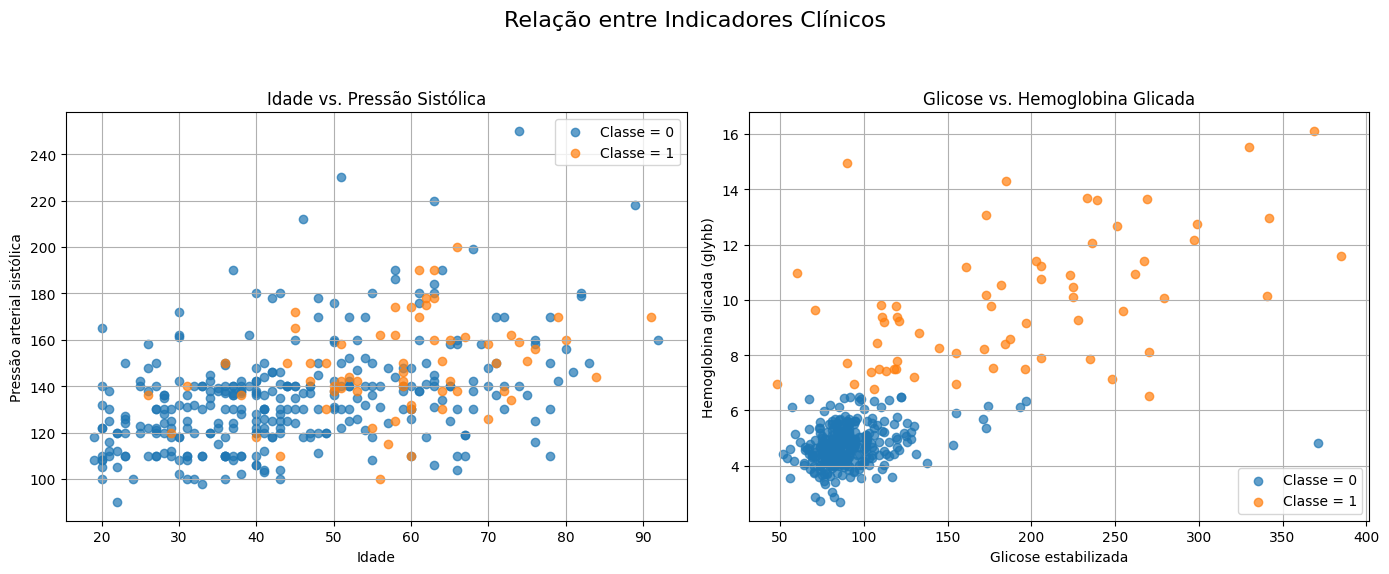

In [321]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Idade vs. Pressão sistólica
for c in sorted(df['Classe'].dropna().unique()):
    grupo = df[df['Classe'] == c]

    axes[0].scatter(grupo['age'], grupo['bp.1s'], label=f'Classe = {int(c)}', alpha=0.7)

axes[0].set_xlabel('Idade')
axes[0].set_ylabel('Pressão arterial sistólica')
axes[0].set_title('Idade vs. Pressão Sistólica')
axes[0].legend()
axes[0].grid(True)

# Gráfico 2: Glicose vs. Hemoglobina glicada
for c in sorted(df['Classe'].dropna().unique()):
    grupo = df[df['Classe'] == c]

    axes[1].scatter(grupo['stab.glu'], grupo['glyhb'], label=f'Classe = {int(c)}', alpha=0.7)

axes[1].set_xlabel('Glicose estabilizada')
axes[1].set_ylabel('Hemoglobina glicada (glyhb)')
axes[1].set_title('Glicose vs. Hemoglobina Glicada')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('Relação entre Indicadores Clínicos', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.93])
plt.show()

No gráfico de idade e pressão sistólica, os grupos apresentam valores bastante sobrepostos, sem uma separação evidente da pressão arterial entre eles. Por outro lado, o gráfico de glicose e hemoglobina glicada mostra uma relação positiva: valores mais elevados de glicose tendem a acompanhar valores mais elevados de hemoglobina glicada. Essa separação entre os grupos é esperada, pois a hemoglobina glicada foi utilizada para definir a classe de diabetes.

## KNN

### Separação - Treino e teste

In [ ]:
# Remover linhas sem hemoglobina glicada
df = df.dropna(subset=['glyhb']).copy()

# Criar o diagnóstico
df['Diabetes'] = (df['glyhb'] >= 6.5).astype(int)

# Selecionar apenas variáveis numéricas
X = df.select_dtypes(include='number').drop(columns=['Diabetes', 'glyhb', 'id'], errors='ignore')

y = df['Diabetes']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

### Avaliação

In [ ]:
knn = KNeighborsClassifier(n_neighbors = 3)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

In [ ]:
knn_prediction = knn.predict(X_test)

In [ ]:
print(f'Acurácia do modelo: {accuracy_score(y_test, knn_prediction)*100}%')

In [ ]:
print("Total de pacientes no teste:", len(y_test))
print("\nDistribuição das classes reais:")
print(y_test.value_counts())

print("\nDistribuição das previsões:")
print(pd.Series(rf_prediction).value_counts())

In [ ]:
display = ConfusionMatrixDisplay(confusion_matrix = confusion_matrix(y_test, knn_prediction), display_labels = ['Não diabético', 'Diabético'])

display.plot()
plt.show()

O modelo KNN apresentou uma acurácia de 87%, indicando que classificou corretamente a maioria dos pacientes do conjunto de teste. Esse resultado demonstra que o modelo conseguiu identificar padrões nos dados, embora tenha cometido alguns erros na classificação.

## Random Forest

### Separação - Treino e teste

In [ ]:
# Remover linhas sem diagnóstico definido
df = df.dropna(subset=['glyhb']).copy()

# Criar a variável-alvo
df['Diabetes'] = (df['glyhb'] >= 6.5).astype(int)

# Selecionar apenas variáveis numéricas
X = df.select_dtypes(include ='number').drop(columns = ['Diabetes', 'glyhb', 'id'], errors ='ignore')

y = df['Diabetes']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

### Avaliação

In [ ]:
modelo_rf = RandomForestClassifier(n_estimators = 100, random_state = 42, class_weight ='balanced')

modelo_rf.fit(X_train, y_train)

rf_prediction = modelo_rf.predict(X_test)

In [ ]:
print(f'Acurácia do modelo: {accuracy_score(y_test, rf_prediction)*100}%')

In [ ]:
print("Total de pacientes no teste:", len(y_test))
print("\nDistribuição das classes reais:")
print(y_test.value_counts())

print("\nDistribuição das previsões:")
print(pd.Series(rf_prediction).value_counts())

In [ ]:
display = ConfusionMatrixDisplay(confusion_matrix = confusion_matrix(y_test, rf_prediction), display_labels = ['Não diabético', 'Diabético'])

display.plot()
plt.show()

In [ ]:
matriz = confusion_matrix(y_test, rf_prediction, labels=[0, 1])

print(matriz)

O modelo Random Forest apresentou uma acurácia de 100% no conjunto de teste, classificando corretamente os 78 pacientes avaliados. O resultado indica que, nesse teste, o modelo não cometeu erros de classificação. Porém, como o conjunto de teste é relativamente pequeno, esse desempenho precisa ser verificado com outras divisões dos dados para avaliar se o modelo mantém bons resultados.

## Comparando resultados

In [ ]:
acuracia_knn = accuracy_score(y_test, y_pred)
acuracia_rf = accuracy_score(y_test, rf_prediction)

print(f'Acurácia do modelo: {accuracy_score(y_test, knn_prediction)*100}%')
print(f'Acurácia do modelo: {accuracy_score(y_test, rf_prediction)*100}%')

Os resultados mostram que os dois modelos conseguiram classificar os pacientes de forma satisfatória, mas o Random Forest se destacou por acertar todas as classificações no conjunto de teste utilizado.

Vale lembrar que a classificação de diabetes foi definida com base na hemoglobina glicada (glyhb), considerando valores iguais ou superiores a 6,5 como indicativo de diabetes. Por isso, é importante levar esse critério em conta ao analisar os resultados.